In [5]:
!unzip my_object_detection.zip

Archive:  my_object_detection.zip
replace my_object_detection/test/images (100).jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [6]:
!pip install tensorflow

In [7]:
import tensorflow as tf
print("TensorFlow 版本:", tf.__version__)

TensorFlow 版本: 2.21.0


In [8]:
import os
import xml.etree.ElementTree as ET

# 檢查資料夾是否存在
train_dir = 'my_object_detection/train'
print("Train 資料夾內容:", os.listdir(train_dir) if os.path.exists(train_dir) else "找不到資料夾")

Train 資料夾內容: ['images (18).jpg', 'images - 2026-10-29T145134.300.jpg', 'images - 2026-10-29T145134.326.jpg', 'images (23).xml', 'images - 2026-10-29T145134.294.xml', 'images - 2026-10-29T145134.320.xml', 'images - 2026-10-29T145134.310.jpg', 'images - 2026-10-29T145134.287.xml', 'images - 2026-10-29T145134.311.xml', 'images (33).xml', 'images - 2026-10-29T145134.315.xml', 'images - 2026-10-29T145134.306.xml', 'images (33).jpg', 'images - 2026-10-29T145134.299.jpg', 'images - 2026-10-29T145134.325.xml', 'images - 2026-10-29T145134.284.jpg', 'images (25).xml', 'images - 2026-10-29T145134.302.xml', 'images - 2026-10-29T145134.316.jpg', 'images - 2026-10-29T145134.296.jpg', 'images - 2026-10-29T145134.318.xml', 'images - 2026-10-29T145134.293.xml', 'images - 2026-10-29T145134.304.xml', 'images - 2026-10-29T145134.297.jpg', 'images - 2026-10-29T145134.317.xml', 'images (12).jpg', 'images - 2026-10-29T145134.298.jpg', 'images (16).xml', 'images - 2026-10-29T145134.323.jpg', '58428.png', 'ima

In [9]:
import glob

# 計算 train 資料夾底下的圖片與 xml 數量
train_images = glob.glob(os.path.join(train_dir, '*.jpg'))
train_xmls = glob.glob(os.path.join(train_dir, '*.xml'))

print(f"訓練集的圖片數量: {len(train_images)}")
print(f"訓練集的 XML 標註數量: {len(train_xmls)}")

訓練集的圖片數量: 91
訓練集的 XML 標註數量: 99


In [10]:
# 自動找出有對應 jpg 的 xml，排除掉多餘的檔案
image_names = set([os.path.splitext(os.path.basename(p))[0] for p in train_images])
xml_names = set([os.path.splitext(os.path.basename(p))[0] for p in train_xmls])

# 找出真正有成對的檔名
valid_names = image_names.intersection(xml_names)
print(f"成功配對的有效資料數量: {len(valid_names)}")

成功配對的有效資料數量: 91


In [11]:
import xml.etree.ElementTree as ET

# 測試解析其中一個 xml 檔案
sample_xml = train_xmls[0]
tree = ET.parse(sample_xml)
root = tree.getroot()

print(f"檔案名稱: {root.find('filename').text}")
for member in root.findall('object'):
    class_name = member.find('name').text
    xmin = int(member.find('bndbox/xmin').text)
    ymin = int(member.find('bndbox/ymin').text)
    xmax = int(member.find('bndbox/xmax').text)
    ymax = int(member.find('bndbox/ymax').text)
    print(f"物件標籤: {class_name}, 座標位置 -> xmin: {xmin}, ymin: {ymin}, xmax: {xmax}, ymax: {ymax}")

檔案名稱: images (23).jpg
物件標籤: lighter, 座標位置 -> xmin: 23, ymin: 10, xmax: 364, ymax: 522


In [12]:
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 建立一個列表來存放處理好的資料
images_data = []
bboxes_data = []

# 遍歷所有的 xml 檔案來讀取影像與對應邊界框
for xml_path in train_xmls:
    tree = ET.parse(xml_path)
    root = tree.getroot()

    # 取得圖片檔名並找出對應的 jpg 路徑
    filename = root.find('filename').text
    img_path = os.path.join(train_dir, filename)

    if os.path.exists(img_path):
        # 讀取圖片並縮放到固定大小 (例如 224x224) 方便訓練
        img = load_img(img_path, target_size=(224, 224))
        img_array = img_to_array(img) / 255.0  # 正規化像素值

        # 讀取第一個標註框座標 (這裡以單一物件為主)
        member = root.find('object')
        if member is not None:
            # 取得原圖尺寸用來做座標歸一化
            size = root.find('size')
            width = int(size.find('width').text)
            height = int(size.find('height').text)

            xmin = int(member.find('bndbox/xmin').text) / width
            ymin = int(member.find('bndbox/ymin').text) / height
            xmax = int(member.find('bndbox/xmax').text) / width
            ymax = int(member.find('bndbox/ymax').text) / height

            images_data.append(img_array)
            bboxes_data.append([xmin, ymin, xmax, ymax])

print(f"成功載入並轉換的訓練樣本數: {len(images_data)}")

成功載入並轉換的訓練樣本數: 96


In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 轉換為 NumPy 陣列
X = np.array(images_data)
y_bbox = np.array(bboxes_data)

print("影像陣列形狀 (X):", X.shape)
print("座標陣列形狀 (y_bbox):", y_bbox.shape)

# 建立一個簡單且輕量的卷積神經網路 (CNN) 模型來做物件偵測（預測邊界框）
base_model = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # 先凍結預訓練權重，加速訓練

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)

# 輸出層：4個節點，分別代表 [xmin, ymin, xmax, ymax] 座標
bbox_output = layers.Dense(4, activation='sigmoid', name='bbox_output')(x)

model = models.Model(inputs=inputs, outputs=bbox_output)

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

影像陣列形狀 (X): (96, 224, 224, 3)
座標陣列形狀 (y_bbox): (96, 4)
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bbox_output (Dense)             │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
# 開始訓練模型，訓練 20 個回合 (Epochs)
history = model.fit(X, y_bbox, epochs=20, batch_size=8, validation_split=0.2)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 515ms/step - loss: 0.0381 - mae: 0.1419 - val_loss: 0.0266 - val_mae: 0.1235
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 372ms/step - loss: 0.0236 - mae: 0.1118 - val_loss: 0.0248 - val_mae: 0.1186
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 325ms/step - loss: 0.0227 - mae: 0.1066 - val_loss: 0.0283 - val_mae: 0.1237
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 404ms/step - loss: 0.0206 - mae: 0.1012 - val_loss: 0.0201 - val_mae: 0.1092
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 400ms/step - loss: 0.0163 - mae: 0.0891 - val_loss: 0.0187 - val_mae: 0.1032
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 432ms/step - loss: 0.0134 - mae: 0.0827 - val_loss: 0.0137 - val_mae: 0.0926
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 341ms/step - loss: 0.0101 - mae: 0.0691 - val_loss: 0.0168 - val_mae: 0.0986
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 341ms/step - loss: 0.0084 - mae: 0.0611 - val_loss: 0.0176 - val_mae: 0.1040
Epoch 9/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 448ms/step - l

模型已成功儲存為 lighter_detector_model.h5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step


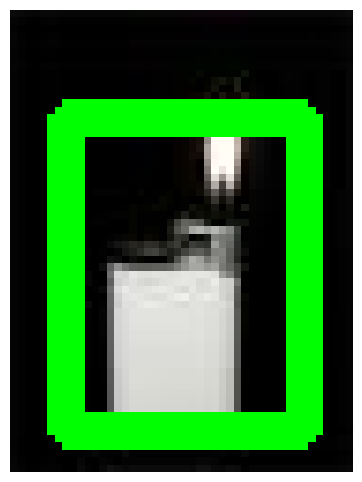

In [17]:
# 1. 儲存模型
model.save('lighter_detector_model.h5')
print("模型已成功儲存為 lighter_detector_model.h5")

# 2. 測試隨機一張圖片的預測結果
import matplotlib.pyplot as plt
import cv2

# 隨機挑選一張圖片來測試
test_img_path = train_images[0]
original_img = cv2.imread(test_img_path)
h, w, _ = original_img.shape

# 預處理圖片
img = load_img(test_img_path, target_size=(224, 224))
img_array = img_to_array(img) / 255.0
img_input = np.expand_dims(img_array, axis=0)

# 進行預測
pred_box = model.predict(img_input)[0]  # 得到 [xmin, ymin, xmax, ymax] (皆為 0~1 的比例)

# 將比例還原成真實圖片的像素座標
xmin = int(pred_box[0] * w)
ymin = int(pred_box[1] * h)
xmax = int(pred_box[2] * w)
ymax = int(pred_box[3] * h)

# 在圖上畫出預測的邊界框
cv2.rectangle(original_img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 3)

# 顯示圖片
original_img_rgb = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 6))
plt.imshow(original_img_rgb)
plt.axis('off')
plt.show()